In [1]:
# Task Complexity Analysis -- source for task-complexity-analysis.ipynb
# (jupytext percent format).
#
# Regenerate notebook + HTML (from the repo root):
#   python -m jupytext --to ipynb notebooks/task-complexity-analysis/task-complexity-analysis.py
#   python -m nbconvert --to notebook --execute --inplace notebooks/task-complexity-analysis/task-complexity-analysis.ipynb
#   python -m nbconvert --to html --no-input notebooks/task-complexity-analysis/task-complexity-analysis.ipynb --output-dir public/analysis/task-complexity-analysis
#
# Google Colab:
#   https://colab.research.google.com/github/shahzorkhan123/metroverse-jobs/blob/master/notebooks/task-complexity-analysis/task-complexity-analysis.ipynb

# Task Complexity Analysis
### How complex are jobs and tasks — and how close are jobs to one another?

*Shahzor Khan · October 2026 · Metroverse-Jobs*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahzorkhan123/metroverse-jobs/blob/master/notebooks/task-complexity-analysis/task-complexity-analysis.ipynb)

---

<details>
<summary><strong>Reproducibility</strong>: click to expand</summary>

### Run on Google Colab (no setup needed)
Click the badge above. The first code cell then:
1. clones the [metroverse-jobs](https://github.com/shahzorkhan123/metroverse-jobs) repository;
2. installs `networkx`, `scipy` and `openpyxl`;
3. downloads the O\*NET 29.3 database from [onetcenter.org](https://www.onetcenter.org/database.html).

BLS employment and wages are read from the JSON files published with the site in `public/data/`.

### Run locally
```bash
git clone https://github.com/shahzorkhan123/metroverse-jobs.git
cd metroverse-jobs
pip install numpy pandas matplotlib networkx scipy openpyxl requests
jupyter notebook notebooks/task-complexity-analysis/task-complexity-analysis.ipynb
```

Every number in this article comes from `scripts/pipeline/compute_space.py`. The website's Occupation Space tab uses the same module.
</details>

---

## Summary

This article explains how the complexity measures and network maps behind the **Occupation Space** tab are computed.

1. **Job Complexity Index (JCI)** and **Task Complexity Index (TCI)** extend the method of reflections from economic complexity to the job × task matrix in O\*NET, starting the iteration from BLS wages. It combines the task-based view of labour markets (Autor, Levy & Murnane, 2003; Acemoglu & Autor, 2011; Acemoglu & Restrepo, 2018) with the economic-complexity toolkit (Hidalgo & Hausmann, 2009). The wage-seeded variant is this article's own exploratory construction, not a published estimator. JCI is measured in dollars and is always positive. After 20 reflections it no longer tracks a job's own pay. Instead it measures the value of the **task family** the job belongs to: healthcare tasks rank highest and production tasks lowest.
2. **Occupation Complexity (PCI)** and **regional complexity (ECI)** apply the standard Atlas of Economic Complexity method to the occupations that US metro areas specialise in.
3. The two **spaces**, or propensity graphs, link occupations that share tasks (Job Space) or that co-locate in the same metros (Occupation Space). A region is more likely to develop occupations close to those it already has.

In [2]:
# --- Setup -----------------------------------------------------------------
import sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("metroverse-jobs").exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/shahzorkhan123/metroverse-jobs.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "networkx>=3.2", "scipy", "openpyxl"], check=True)
    ROOT = Path("metroverse-jobs").resolve()
else:
    ROOT = Path.cwd().resolve()
    while not (ROOT / "scripts" / "pipeline").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "public" / "data"
ONET_ZIP = ROOT / "data" / "raw" / "db_29_3_excel.zip"
if not ONET_ZIP.exists():
    import requests
    ONET_ZIP.parent.mkdir(parents=True, exist_ok=True)
    r = requests.get("https://www.onetcenter.org/dl_files/database/db_29_3_excel.zip",
                     headers={"User-Agent": "Mozilla/5.0"}, timeout=300)
    r.raise_for_status()
    ONET_ZIP.write_bytes(r.content)
FIG_DIR = ROOT / "public" / "analysis" / "task-complexity-analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display, Markdown
from scripts.pipeline import compute_space as cs

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
pd.set_option("display.max_colwidth", 70)

oes = cs.load_oes_level4(DATA_DIR, "us", 2024)
occ = pd.DataFrame.from_dict(oes["occupations"], orient="index")
occ["emp"] = pd.Series(oes["emp"][oes["national_id"]])
occ["wage"] = pd.Series(oes["wage"])
with open(DATA_DIR / "bls-data-us-2024.json", encoding="utf-8") as f:
    MG_COLOR = {g["groupId"]: g["color"] for g in json.load(f)["majorGroups"]}
pairs, dwa_titles = cs.load_onet_job_dwa(ONET_ZIP)
MG_SHORT = {gid: cs.SHORT_GROUP_NAMES.get(name, name)
            for gid, name in occ.groupby("majorGroupId").majorGroupName.first().items()}

def mg_legend(fig, group_ids, ncol=6, y=-0.02):
    """Colour key for SOC major groups, placed under the figure."""
    from matplotlib.lines import Line2D
    ids = sorted(set(group_ids) & set(MG_SHORT))
    handles = [Line2D([], [], marker="o", ls="", color=MG_COLOR.get(g, "#999"), markersize=7,
                      label=f"{g} {MG_SHORT[g]}") for g in ids]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, y), ncol=ncol,
               fontsize=8, frameon=False, title="SOC major group", title_fontsize=8.5)

## 1. Motivation: jobs as bundles of tasks

The **task framework** treats a job as a bundle of tasks. Technology acts on tasks, either automating them or making workers more productive at them, rather than on whole occupations:

- Autor, Levy & Murnane (2003) showed that computers substitute for *routine* tasks and complement *non-routine* analytical and interactive ones.
- Acemoglu & Autor (2011) formalised this as a Ricardo-Roy model in which skills are assigned to tasks by comparative advantage.
- Acemoglu & Restrepo (2018, 2019, 2022) model technology as shifting the *task content of production*: automation **displaces** labour from tasks it used to perform, while the creation of **new tasks** reinstates it. Their 2022 paper attributes most of the rise in US wage inequality since 1980 to task displacement.

The difficulty is that only *jobs* have observable prices, in the form of wages. *Tasks* do not.

**Economic complexity** offers a way round this. Hausmann & Hidalgo (2011) describe production with a **Scrabble analogy**: capabilities are letters, products are words, and a country can only spell words for which it holds all the letters. Hidalgo & Hausmann (2009) showed that the hidden capabilities can be recovered from the observable country × product matrix with the *method of reflections*.

Applied to labour, the analogy becomes: workers hold hidden capabilities (skills, the letters); each task needs a combination of them; and a job is a word built from tasks. Jobs that share many tasks draw on the same letters.

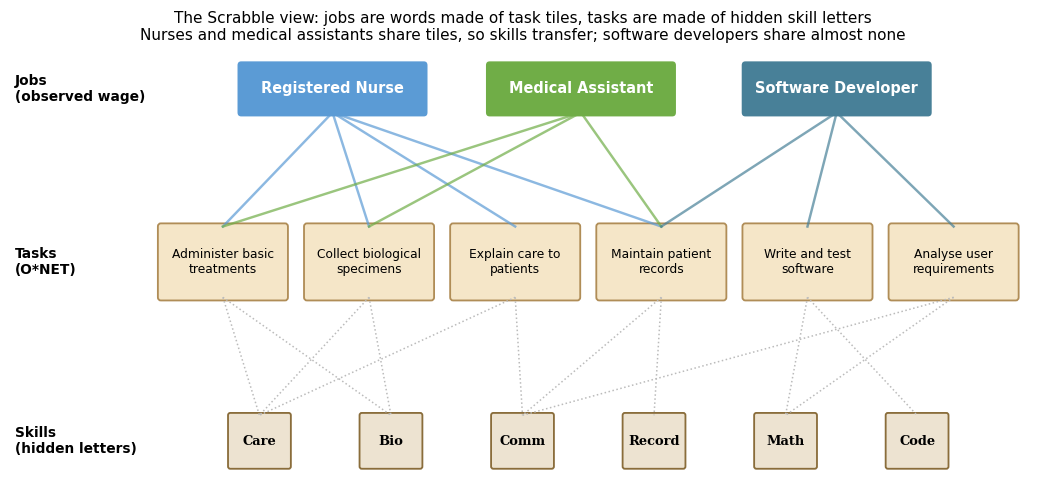

In [3]:
def scrabble_diagram():
    """Explanatory figure: skills (letters) -> tasks (tiles) -> jobs (words)."""
    from matplotlib.patches import FancyBboxPatch
    skills = ["Care", "Bio", "Comm", "Record", "Math", "Code"]
    tasks = {
        "Administer basic\ntreatments": ["Care", "Bio"],
        "Collect biological\nspecimens": ["Bio", "Care"],
        "Explain care to\npatients": ["Comm", "Care"],
        "Maintain patient\nrecords": ["Record", "Comm"],
        "Write and test\nsoftware": ["Code", "Math"],
        "Analyse user\nrequirements": ["Comm", "Math"],
    }
    jobs = {"Registered Nurse": [0, 1, 2, 3], "Medical Assistant": [0, 1, 3],
            "Software Developer": [4, 5, 3]}
    jcol = {"Registered Nurse": MG_COLOR.get("29", "#c55"), "Medical Assistant": MG_COLOR.get("31", "#e88"),
            "Software Developer": MG_COLOR.get("15", "#58a")}
    fig, ax = plt.subplots(figsize=(12, 5.2))
    ax.set_xlim(-1.9, 12.1); ax.set_ylim(0, 5.6); ax.axis("off")
    tx = {t: 1.0 + 2.0 * i for i, t in enumerate(tasks)}
    sx = {s: 1.5 + 1.8 * i for i, s in enumerate(skills)}
    jx = {"Registered Nurse": 2.5, "Medical Assistant": 5.9, "Software Developer": 9.4}
    ax.text(-1.85, 5.1, "Jobs\n(observed wage)", fontsize=9, weight="bold", va="center")
    ax.text(-1.85, 2.9, "Tasks\n(O*NET)", fontsize=9, weight="bold", va="center")
    ax.text(-1.85, 0.62, "Skills\n(hidden letters)", fontsize=9, weight="bold", va="center")
    for j, ts in jobs.items():
        for t in ts:
            ax.plot([jx[j], tx[list(tasks)[t]]], [4.8, 3.35], color=jcol[j], lw=1.6, alpha=0.7)
        ax.add_patch(FancyBboxPatch((jx[j] - 1.25, 4.8), 2.5, 0.6, boxstyle="round,pad=0.05",
                                    fc=jcol[j], ec="none"))
        ax.text(jx[j], 5.1, j, ha="center", va="center", color="white", fontsize=9.5, weight="bold")
    for t, ss in tasks.items():
        for s in ss:
            ax.plot([tx[t], sx[s]], [2.45, 0.95], color="#bbb", lw=1, ls=":")
        ax.add_patch(FancyBboxPatch((tx[t] - 0.85, 2.45), 1.7, 0.9, boxstyle="round,pad=0.04",
                                    fc="#F5E6C8", ec="#B08D57", lw=1.2))
        ax.text(tx[t], 2.9, t, ha="center", va="center", fontsize=8)
    for s in skills:
        ax.add_patch(FancyBboxPatch((sx[s] - 0.4, 0.3), 0.8, 0.65, boxstyle="round,pad=0.03",
                                    fc="#EDE3D1", ec="#8a6d3b", lw=1.2))
        ax.text(sx[s], 0.62, s, ha="center", va="center", fontsize=8.5, weight="bold", family="serif")
    ax.set_title("The Scrabble view: jobs are words made of task tiles, tasks are made of hidden skill letters\n"
                 "Nurses and medical assistants share tiles, so skills transfer; software developers share almost none",
                 fontsize=10)
    plt.savefig(FIG_DIR / "00a_scrabble.png", bbox_inches="tight", dpi=120); plt.show()

scrabble_diagram()

(Task labels are simplified from real O\*NET DWAs. In the data, registered nurses list 66 DWAs and medical assistants 21; they share patient-care activities such as *Administer basic health care or medical treatments* and *Collect biological specimens from patients*.)

We never observe skills directly. We do observe:

- which tasks each job performs (O\*NET);
- what each job is paid (BLS).

Economic complexity has a standard way to recover a hidden variable from a bipartite matrix like this: alternately average over the two sides of the matrix. This is the **method of reflections**.

Two assumptions motivate seeding that iteration with wages:

- **A1 (competitive labour market):** the wage $\omega_j$ equals the value added by the tasks the job performs, $\omega_j = \sum_i \tau_i N_{ji}$.
- **A2 (equal productivity within a job):** a worker spreads time across tasks until the marginal productivity is the same everywhere, so $A_{ji} = A_j$ and $\omega_j = A_j$.

Under these assumptions a task's value is the average wage of the jobs that perform it. A job's value, in turn, depends on how valuable its tasks are elsewhere. Iterating these two averages gives the Job and Task Complexity Indices.

## 2. Data

| Source | What we use | Notes |
|---|---|---|
| **O\*NET 29.3** (Nov 2024), *Tasks to DWAs* | Job → Detailed Work Activity links | About 2,000 DWAs. O\*NET-SOC detail codes (e.g. `15-1252.00`) are collapsed to 6-digit SOC by taking the union of their DWAs. |
| **BLS OES May 2024**, national | Mean annual wage and employment per detailed occupation | Used as the seed wage $\omega_j$ |
| **BLS OES May 2024**, metro areas | Employment by metro × detailed occupation | 393 metros. Suppressed cells count as 0. |

In [4]:
jobs_onet = {j for j, _ in pairs}
coverage = pd.DataFrame({
    "": ["Detailed occupations in OES 2024", "…with a national mean wage", "Jobs in O*NET with DWAs",
         "Jobs in both (Job Space nodes)", "Detailed Work Activities (DWAs)"],
    "count": [len(occ), occ.wage.notna().sum(), len(jobs_onet),
              len(jobs_onet & set(occ.index[occ.wage.notna()])), len(dwa_titles)],
})
display(coverage.set_index(""))

,count
,
Detailed occupations in OES 2024,819
…with a national mean wage,819
Jobs in O*NET with DWAs,798
Jobs in both (Job Space nodes),768
Detailed Work Activities (DWAs),2082


## 3. The job × task matrix

We set $M_{JT} = 1$ when O\*NET lists task (DWA) $T$ among the activities of job $J$, and 0 otherwise. In exploratory runs this binary version ("Model 1") behaved much like weighting by O\*NET importance or by importance × relevance × frequency, and it is the most transparent of the three. Listing a task is itself a kind of *revealed* comparative advantage.

Two quantities describe the matrix:
- **Diversity** of a job: $K_{J,0} = \sum_T M_{JT}$, the number of tasks it performs.
- **Ubiquity** of a task: $K_{T,0} = \sum_J M_{JT}$, the number of jobs that perform it.

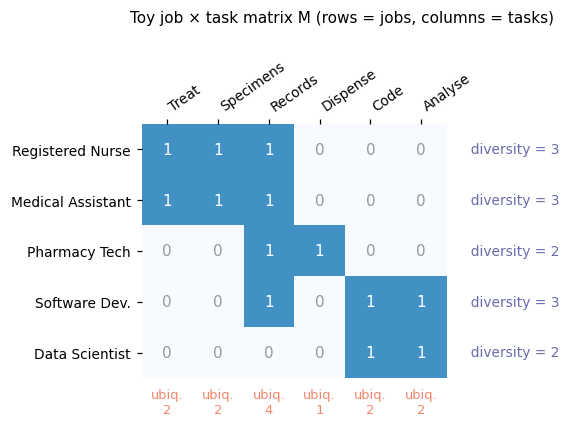

In [5]:
def matrix_diagram():
    """Explanatory figure: a toy job x task matrix with diversity and ubiquity."""
    jobs_ = ["Registered Nurse", "Medical Assistant", "Pharmacy Tech", "Software Dev.", "Data Scientist"]
    tasks_ = ["Treat", "Specimens", "Records", "Dispense", "Code", "Analyse"]
    Mt = np.array([[1, 1, 1, 0, 0, 0],
                   [1, 1, 1, 0, 0, 0],
                   [0, 0, 1, 1, 0, 0],
                   [0, 0, 1, 0, 1, 1],
                   [0, 0, 0, 0, 1, 1]])
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.imshow(Mt, cmap="Blues", vmin=0, vmax=1.6)
    for i in range(Mt.shape[0]):
        for j in range(Mt.shape[1]):
            ax.text(j, i, int(Mt[i, j]), ha="center", va="center", fontsize=10,
                    color="white" if Mt[i, j] else "#999")
        ax.text(Mt.shape[1] - 0.2, i, f"  diversity = {Mt[i].sum()}", va="center", fontsize=9, color="#6A6AAD")
    for j in range(Mt.shape[1]):
        ax.text(j, Mt.shape[0] - 0.3, f"ubiq.\n{Mt[:, j].sum()}", ha="center", va="top", fontsize=8.5, color="#F1866C")
    ax.set_xticks(range(len(tasks_))); ax.set_xticklabels(tasks_, fontsize=9, rotation=35, ha="left")
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(jobs_))); ax.set_yticklabels(jobs_, fontsize=9)
    ax.set_xlim(-0.5, Mt.shape[1] + 1.4); ax.set_ylim(Mt.shape[0] + 0.5, -0.5)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title("Toy job × task matrix M (rows = jobs, columns = tasks)", fontsize=10, pad=24)
    plt.savefig(FIG_DIR / "00b_matrix.png", bbox_inches="tight", dpi=120); plt.show()

matrix_diagram()

"Records" is ubiquitous (4 of 5 jobs), so performing it says little about a job. "Dispense" is performed by one job only. The real matrix below has the same structure at scale:

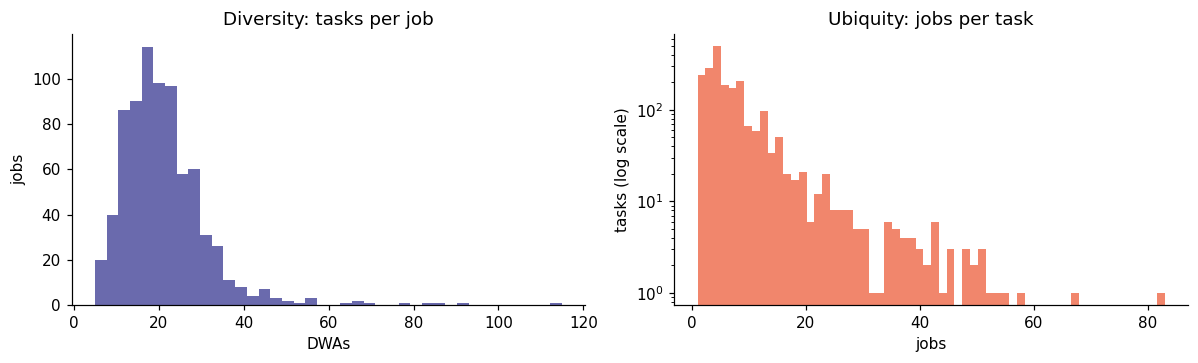

Matrix: 768 jobs × 2072 tasks, 16,290 links (density 1.024%); median job performs 20 DWAs


In [6]:
job_space = cs.build_job_space(oes, pairs, n_iter=20)
M = job_space["M"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(M.sum(1), bins=40, color="#6A6AAD")
ax[0].set(title="Diversity: tasks per job", xlabel="DWAs", ylabel="jobs")
ax[1].hist(M.sum(0), bins=60, color="#F1866C", log=True)
ax[1].set(title="Ubiquity: jobs per task", xlabel="jobs", ylabel="tasks (log scale)")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_matrix_degrees.png", bbox_inches="tight"); plt.show()
print(f"Matrix: {M.shape[0]} jobs × {M.shape[1]} tasks, {int(M.sum()):,} links "
      f"(density {M.mean():.3%}); median job performs {int(np.median(M.sum(1)))} DWAs")

## 4. Job and Task Complexity: wage-seeded reflections

**Stage 1 (seed).** The value of a job starts at its wage, and the value of a task starts at the average wage of the jobs that perform it:
$$K_{J,1} = \omega_J, \qquad K_{T,1} = \frac{1}{K_{T,0}}\sum_J M_{JT}\,\omega_J = \big(D_T^{-1}M^\top\big)\,\omega$$

**Stage N (reflections).** Jobs and tasks then correct each other:
$$K_{J,N} = \big(D_J^{-1}M\big)K_{T,N-1}, \qquad K_{T,N} = \big(D_T^{-1}M^\top\big)K_{J,N-1}$$
Two steps combine into a single job-to-job operator and a single task-to-task operator:
$$\tilde M_{JJ} = D_J^{-1} M\, D_T^{-1} M^\top, \qquad \tilde M_{TT} = D_T^{-1} M^\top D_J^{-1} M$$
$$\text{JCI} = \tilde M_{JJ}^{\,n}\,\omega, \qquad \text{TCI} = \tilde M_{TT}^{\,n}\,K_{T,1}$$

Here $D_J = \mathrm{diag}(K_{J,0})$ and $D_T = \mathrm{diag}(K_{T,0})$.

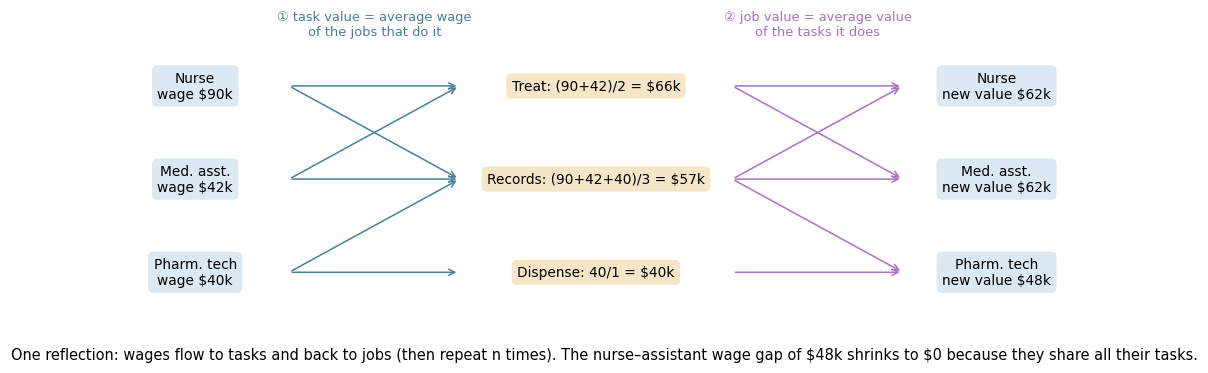

In [7]:
def reflections_diagram():
    """Explanatory figure: one round of wage-seeded reflections on the toy matrix."""
    fig, ax = plt.subplots(figsize=(12, 3.6))
    ax.set_xlim(0, 12); ax.set_ylim(0, 3.6); ax.axis("off")
    jobs_ = [("Nurse", 90), ("Med. asst.", 42), ("Pharm. tech", 40)]
    tasks_ = [("Treat", "(90+42)/2", 66), ("Records", "(90+42+40)/3", 57), ("Dispense", "40/1", 40)]
    links = [(0, 0), (0, 1), (1, 0), (1, 1), (2, 1), (2, 2)]
    new_j = [(66 + 57) / 2, (66 + 57) / 2, (57 + 40) / 2]
    def box(x, y, txt, fc):
        ax.text(x, y, txt, ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.4", fc=fc, ec="none"))
    for k, (j, w) in enumerate(jobs_):
        box(1.2, 2.9 - k * 1.1, f"{j}\nwage \\${w}k", "#DCE8F2")
        box(10.6, 2.9 - k * 1.1, f"{j}\nnew value \\${new_j[k]:.0f}k", "#DCE8F2")
    for k, (t, f, v) in enumerate(tasks_):
        box(5.9, 2.9 - k * 1.1, f"{t}: {f} = \\${v}k", "#F5E6C8")
    for j, t in links:
        ax.annotate("", xy=(4.3, 2.9 - t * 1.1), xytext=(2.3, 2.9 - j * 1.1),
                    arrowprops=dict(arrowstyle="->", color="#488098", lw=1))
        ax.annotate("", xy=(9.5, 2.9 - j * 1.1), xytext=(7.5, 2.9 - t * 1.1),
                    arrowprops=dict(arrowstyle="->", color="#A973BE", lw=1))
    ax.text(3.3, 3.5, "① task value = average wage\nof the jobs that do it", ha="center", fontsize=8.5, color="#488098")
    ax.text(8.5, 3.5, "② job value = average value\nof the tasks it does", ha="center", fontsize=8.5, color="#A973BE")
    ax.set_title("One reflection: wages flow to tasks and back to jobs (then repeat n times). "
                 "The nurse–assistant wage gap of \\$48k shrinks to \\$0 because they share all their tasks.",
                 fontsize=9.5, y=-0.12)
    plt.savefig(FIG_DIR / "00c_reflections.png", bbox_inches="tight", dpi=120); plt.show()

reflections_diagram()
#
# **Why iterate instead of taking the eigenvector?** The Atlas defines complexity as the second eigenvector of $\tilde M$. Eigenvectors have no units, and their sign is arbitrary. On the job × task matrix the eigenvector solution produced *negative* complexities for some jobs, which cannot be read as value added. (Mealy, Farmer & Teytelboym, 2019, show that the eigenvector is best read as a spectral-clustering coordinate that orders nodes along the matrix's main axis of similarity, not as a level of value.) Both operators are row-stochastic, meaning every row is a weighted average. Each multiplication therefore keeps the values in dollars and positive, and it shrinks the dispersion a little each time. After $n$ steps a job's JCI is its wage smoothed over a neighbourhood $n$ steps wide in the job-task network. Iterating without limit would collapse every value towards a single weighted mean wage.
#
# We use $n = 20$. The figure below shows what that choice does:
#
# - **Dispersion falls fast.** The coefficient of variation drops from about 0.64 (raw wages) to about 0.1.
# - **The ranking settles by n ≈ 10.** Its Spearman correlation with the n = 20 ranking is above 0.95 from there on.
#
# By n = 20, therefore, JCI has mostly averaged away differences *within* a group of jobs that share tasks. What remains is the difference *between* such groups. Smaller values of $n$ keep more of a job's own wage. The `N_ITER` knob in the playground notebook lets you explore this trade-off.

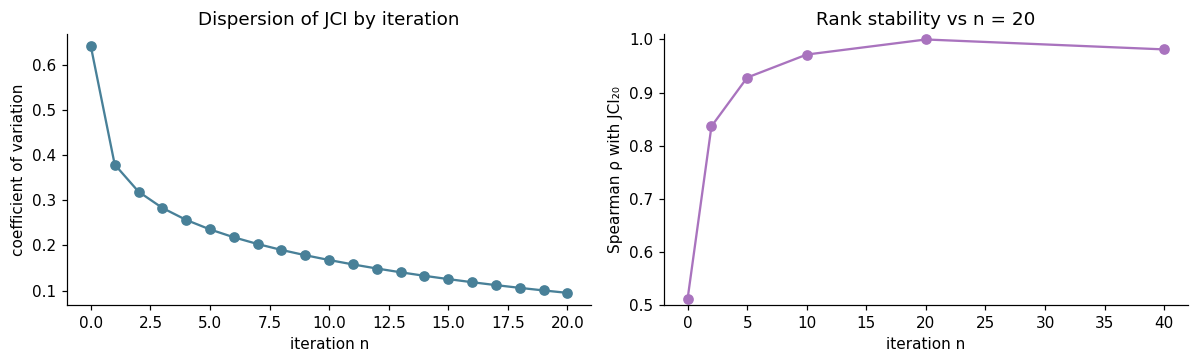

In [8]:
jci_by_n = {}
for n in (0, 2, 5, 10, 20, 40):
    jci_n, _, _ = cs.wage_seeded_jci(M, job_space["wages"], n_iter=n)
    jci_by_n[n] = jci_n
hist = job_space["history"]
ref = jci_by_n[20]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(range(len(hist)), hist, marker="o", color="#488098")
ax[0].set(title="Dispersion of JCI by iteration", xlabel="iteration n", ylabel="coefficient of variation")
ns = sorted(jci_by_n)
ax[1].plot(ns, [spearmanr(jci_by_n[n], ref).correlation for n in ns], marker="o", color="#A973BE")
ax[1].set(title="Rank stability vs n = 20", xlabel="iteration n", ylabel="Spearman ρ with JCI₂₀", ylim=(0.5, 1.01))
plt.tight_layout(); plt.savefig(FIG_DIR / "02_convergence.png", bbox_inches="tight"); plt.show()

## 5. Results

### 5.1 The most and least complex jobs

In [9]:
occ["jci"] = pd.Series(job_space["jci"])
d = occ.dropna(subset=["jci"]).copy()
cols = {"name": "Occupation", "majorGroupName": "Major group", "wage": "Mean wage ($)", "jci": "JCI ($)"}
fmt = lambda t: t[list(cols)].rename(columns=cols).style.format({"Mean wage ($)": "{:,.0f}", "JCI ($)": "{:,.0f}"}).hide(axis="index")
display(Markdown("**Top 15 by Job Complexity Index**"))
display(fmt(d.sort_values("jci", ascending=False).head(15)))
display(Markdown("**Bottom 10**"))
display(fmt(d.sort_values("jci").head(10)))

**Top 15 by Job Complexity Index**

Occupation,Major group,Mean wage ($),JCI ($)
Optometrists,Healthcare Practitioners and Technical,"140,940","102,693"
Dermatologists,Healthcare Practitioners and Technical,"347,810","102,683"
"Ophthalmologists, Except Pediatric",Healthcare Practitioners and Technical,"301,500","102,534"
Neurologists,Healthcare Practitioners and Technical,"286,310","102,532"
"Orthopedic Surgeons, Except Pediatric",Healthcare Practitioners and Technical,"365,060","102,483"
Podiatrists,Healthcare Practitioners and Technical,"163,960","102,478"
Nurse Practitioners,Healthcare Practitioners and Technical,"132,000","102,421"
"Healthcare Diagnosing or Treating Practitioners, All Other",Healthcare Practitioners and Technical,"128,680","102,415"
Psychiatrists,Healthcare Practitioners and Technical,"269,120","102,388"
Acupuncturists,Healthcare Practitioners and Technical,"89,750","102,381"


**Bottom 10**

Occupation,Major group,Mean wage ($),JCI ($)
Slaughterers and Meat Packers,Production,"40,710","71,257"
"Meat, Poultry, and Fish Cutters and Trimmers",Production,"38,640","71,812"
Fabric and Apparel Patternmakers,Production,"71,630","71,837"
"Tailors, Dressmakers, and Custom Sewers",Production,"44,050","71,910"
Sewing Machine Operators,Production,"36,680","71,972"
"Layout Workers, Metal and Plastic",Production,"65,770","71,984"
Etchers and Engravers,Production,"43,280","72,015"
"Milling and Planing Machine Setters, Operators, and Tenders, Metal and Plastic",Production,"52,940","72,049"
"Cutters and Trimmers, Hand",Production,"41,960","72,054"
"Forging Machine Setters, Operators, and Tenders, Metal and Plastic",Production,"50,900","72,104"


### 5.2 The most complex tasks
A task's TCI is high when the jobs that perform it are themselves complex, *after* accounting for everything else those jobs do.

In [10]:
tci = pd.Series(job_space["tci"]).sort_values(ascending=False)
jobs_per_task = pd.Series(M.sum(0), index=job_space["tasks"])
display(pd.DataFrame({
    "Detailed Work Activity": [dwa_titles[t] for t in tci.index[:15]],
    "TCI ($)": tci.values[:15],
    "Jobs performing it": jobs_per_task[tci.index[:15]].astype(int).values,
}).style.format({"TCI ($)": "{:,.0f}"}).hide(axis="index"))

Detailed Work Activity,TCI ($),Jobs performing it
Advise patients on preventive care techniques.,"102,396",3
Schedule medical facility use.,"102,373",1
Treat chronic diseases or disorders.,"102,216",16
Prescribe treatments or therapies.,"102,152",17
Care for women during pregnancy and childbirth.,"102,087",3
Prescribe medications.,"102,069",25
Prescribe assistive medical devices or related treatments.,"102,061",5
Operate on patients to treat conditions.,"102,008",18
Order medical diagnostic or clinical tests.,"101,994",17
Analyze test data or images to inform diagnosis or treatment.,"101,974",29


### 5.3 JCI against wages and occupational families

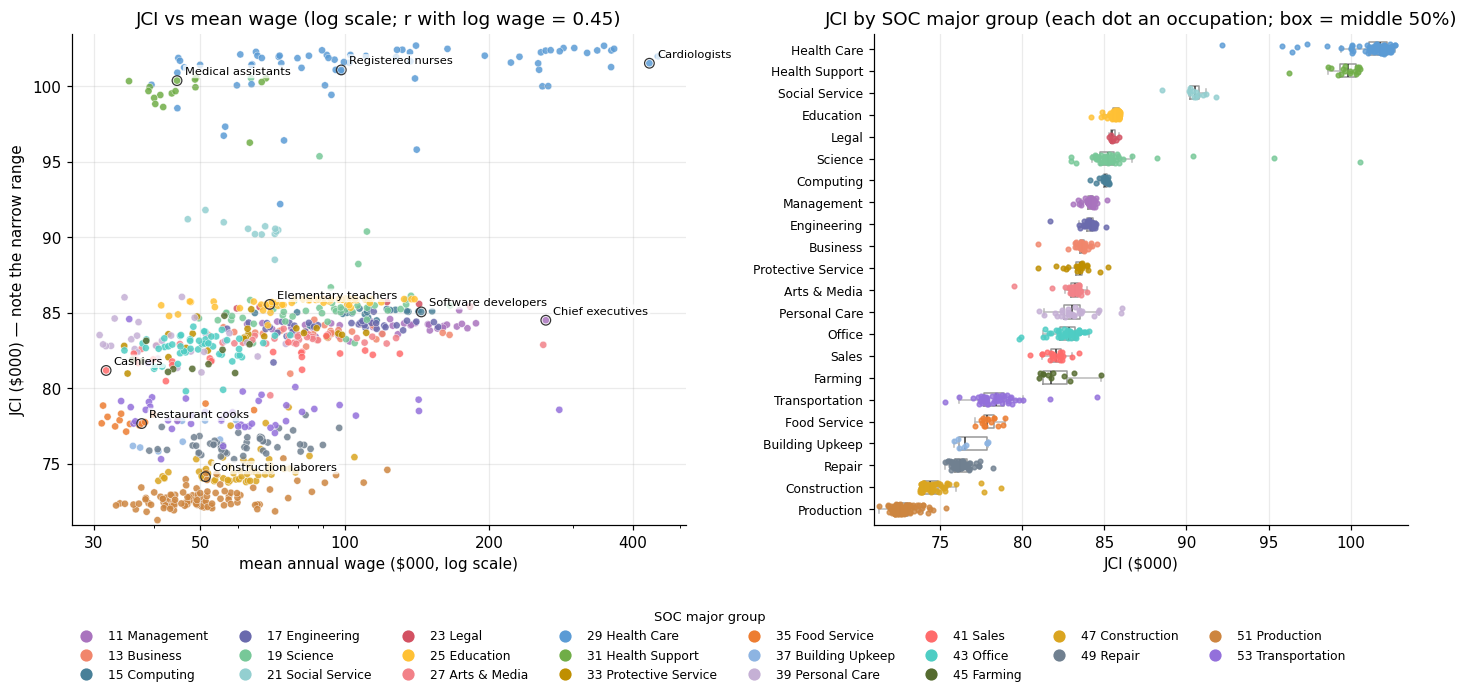

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
c = [MG_COLOR.get(g, "#999") for g in d.majorGroupId]
ax[0].scatter(d.wage / 1000, d.jci / 1000, s=22, c=c, alpha=0.85, edgecolors="white", linewidths=0.3)
ax[0].set_xscale("log")
ax[0].set_xticks([30, 50, 100, 200, 400]); ax[0].set_xticklabels(["30", "50", "100", "200", "400"])
lo, hi = d.jci.quantile([0.005, 0.995]) / 1000
ax[0].set_ylim(lo - 1, hi + 1)
r = np.corrcoef(np.log(d.wage), d.jci)[0, 1]
EXEMPLARS = {"29-1141": "Registered nurses", "31-9092": "Medical assistants", "15-1252": "Software developers",
             "41-2011": "Cashiers", "29-1212": "Cardiologists", "47-2061": "Construction laborers",
             "51-2098": "Assemblers", "25-2021": "Elementary teachers", "11-1011": "Chief executives",
             "35-2014": "Restaurant cooks"}
for code, label in EXEMPLARS.items():
    if code in d.index:
        x, y = d.loc[code, "wage"] / 1000, d.loc[code, "jci"] / 1000
        ax[0].annotate(label, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=7.5,
                       bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
        ax[0].scatter([x], [y], s=40, facecolors="none", edgecolors="#333", linewidths=0.8)
ax[0].set(title=f"JCI vs mean wage (log scale; r with log wage = {r:.2f})",
          xlabel="mean annual wage ($000, log scale)", ylabel="JCI ($000) — note the narrow range")
ax[0].grid(alpha=0.25)
order = d.groupby("majorGroupId").jci.median().sort_values()
rng = np.random.default_rng(0)
for k, g in enumerate(order.index):
    v = d.loc[d.majorGroupId == g, "jci"] / 1000
    ax[1].boxplot(v, positions=[k], vert=False, widths=0.6, showfliers=False,
                  medianprops=dict(color="#333"), boxprops=dict(color="#999"),
                  whiskerprops=dict(color="#bbb"), capprops=dict(color="#bbb"))
    ax[1].scatter(v, k + rng.uniform(-0.22, 0.22, len(v)), s=9, color=MG_COLOR.get(g, "#999"), alpha=0.8, zorder=3)
ax[1].set_yticks(range(len(order))); ax[1].set_yticklabels([MG_SHORT.get(g, g) for g in order.index], fontsize=8)
ax[1].set_ylim(-0.7, len(order) - 0.3)
ax[1].set_xlim(lo - 1, hi + 1)
ax[1].set(title="JCI by SOC major group (each dot an occupation; box = middle 50%)", xlabel="JCI ($000)")
ax[1].grid(axis="x", alpha=0.25)
plt.tight_layout()
mg_legend(fig, d.majorGroupId.unique(), ncol=8)
plt.savefig(FIG_DIR / "03_jci_wage_groups.png", bbox_inches="tight", dpi=120); plt.show()

**How to read this figure.** Mean wages span more than a factor of ten, from about \$30k to over \$400k. JCI spans only about \$70k–\$105k, so the y-axis is zoomed in to make the differences visible.

- **Horizontal bands are task families.** After 20 reflections, every job's value is averaged with the jobs it shares tasks with, then with *their* neighbours, and so on. Jobs that share most of their DWAs converge to almost the same value, whatever they are paid. Each colour therefore forms a flat band rather than following the wage axis.
- **Health care sits at the top.** Registered nurses and medical assistants earn very different wages, but they share patient-care DWAs, so both reach the top band (≈ \$100k). Physicians and surgeons (\$300k–\$450k, e.g. cardiologists) sit in the same band: their premium comes from credentials and scarcity, not from a different task family.
- **Production, construction, repair, building upkeep and food service sit at the bottom** (≈ \$71k–\$79k). They share machine-, material- and food-handling tasks that are also performed by many low-wage jobs.
- **The slope is shallow but positive** (r with log wage shown in the title): better-paid jobs tend to do tasks that are also done in better-paid jobs, but the task family explains much more than the job's own pay.

JCI is therefore best read as the **market value of a job's task bundle**. The difference *wage − JCI* is the premium (or discount) a job earns over the tasks it performs. Large premia point to scarce credentials, licensing or rents; large discounts to jobs that perform valued tasks in low-paying settings.

In [12]:
d["premium"] = d.wage - d.jci
pcols = {"name": "Occupation", "majorGroupName": "Major group", "wage": "Mean wage ($)",
         "jci": "JCI ($)", "premium": "Wage − JCI ($)"}
pfmt = lambda t: (t[list(pcols)].rename(columns=pcols)
                  .style.format({"Mean wage ($)": "{:,.0f}", "JCI ($)": "{:,.0f}", "Wage − JCI ($)": "{:+,.0f}"})
                  .hide(axis="index"))
display(Markdown("**Largest premia: paid well above the value of their task bundle**"))
display(pfmt(d.sort_values("premium", ascending=False).head(8)))
display(Markdown("**Largest discounts: paid well below the value of their task bundle**"))
display(pfmt(d.sort_values("premium").head(8)))

**Largest premia: paid well above the value of their task bundle**

Occupation,Major group,Mean wage ($),JCI ($),Wage − JCI ($)
Pediatric Surgeons,Healthcare Practitioners and Technical,"450,810","101,977","+348,833"
Cardiologists,Healthcare Practitioners and Technical,"432,490","101,525","+330,965"
"Orthopedic Surgeons, Except Pediatric",Healthcare Practitioners and Technical,"365,060","102,483","+262,577"
Radiologists,Healthcare Practitioners and Technical,"359,820","101,267","+258,553"
Oral and Maxillofacial Surgeons,Healthcare Practitioners and Technical,"360,240","102,373","+257,867"
Dermatologists,Healthcare Practitioners and Technical,"347,810","102,683","+245,127"
Anesthesiologists,Healthcare Practitioners and Technical,"336,640","102,373","+234,267"
Emergency Medicine Physicians,Healthcare Practitioners and Technical,"320,700","102,209","+218,491"


**Largest discounts: paid well below the value of their task bundle**

Occupation,Major group,Mean wage ($),JCI ($),Wage − JCI ($)
Physical Therapist Aides,Healthcare Support,"35,510","100,340","-64,830"
Medical Transcriptionists,Healthcare Support,"39,210","99,950","-60,740"
Veterinary Assistants and Laboratory Animal Caretakers,Healthcare Support,"38,990","99,684","-60,694"
Dietetic Technicians,Healthcare Practitioners and Technical,"39,560","100,099","-60,539"
Orderlies,Healthcare Support,"40,070","99,227","-59,157"
Pharmacy Aides,Healthcare Support,"40,290","98,827","-58,537"
Nursing Assistants,Healthcare Support,"41,270","99,420","-58,150"
Psychiatric Technicians,Healthcare Practitioners and Technical,"45,000","101,873","-56,873"


### 5.4 Reading JCI and TCI through the task framework

In Acemoglu & Restrepo's framework, the wage bill of an occupation is the value of the tasks assigned to labour in it. Automation removes tasks from that set (**displacement**); new tasks add to it (**reinstatement**). Their empirical work measures these shifts at the industry level, because task-level prices are not observed.

TCI supplies a candidate price: it is the wage-implied value of a task, the average of the values of the jobs that perform it. This allows a simple accounting:

- if technology automates a set of tasks $A$ inside job $j$, the job's task bundle loses $\sum_{t \in A} \mathrm{TCI}_t / K_{j,0}$ of value, and its JCI falls unless new tasks are added;
- a job whose remaining tasks have high TCI is more insulated, and its neighbours in the Job Space show where its workers' skills transfer.

This is a descriptive bridge, not a structural estimate: TCI inherits the wage distortions noted in §8, and the iteration count shapes how much of a job's own pay remains. Linking TCI to measures of automation exposure (e.g. routine-task intensity, Autor, Levy & Murnane 2003) is a natural next step.

## 6. Occupation Complexity from where jobs locate (PCI / ECI)

The second measure ignores task content. It looks only at **which metros specialise in which occupations**, applying the Atlas of Economic Complexity method (Hidalgo & Hausmann, 2009; Hausmann et al., 2014) to BLS metro employment $X_{cp}$:

$$RCA_{cp} = \frac{X_{cp}/\sum_{p} X_{cp}}{\sum_c X_{cp}/\sum_{c,p} X_{cp}}, \qquad M_{cp} = \mathbb 1[RCA_{cp}\ge 1]$$

**PCI** is the eigenvector for the second-largest eigenvalue of $\tilde M^P = U^{-1}M^\top D^{-1}M$, where $D$ is the diagonal matrix of metro diversities and $U$ the diagonal matrix of occupation ubiquities. **ECI** is the matching eigenvector for metros. Both are signed and z-scored following the py-ecomplexity conventions (ECI rises with diversity). Our implementation agrees with Growth Lab's `py-ecomplexity` package (correlation above 0.999, see `tests/test_compute_space.py`).

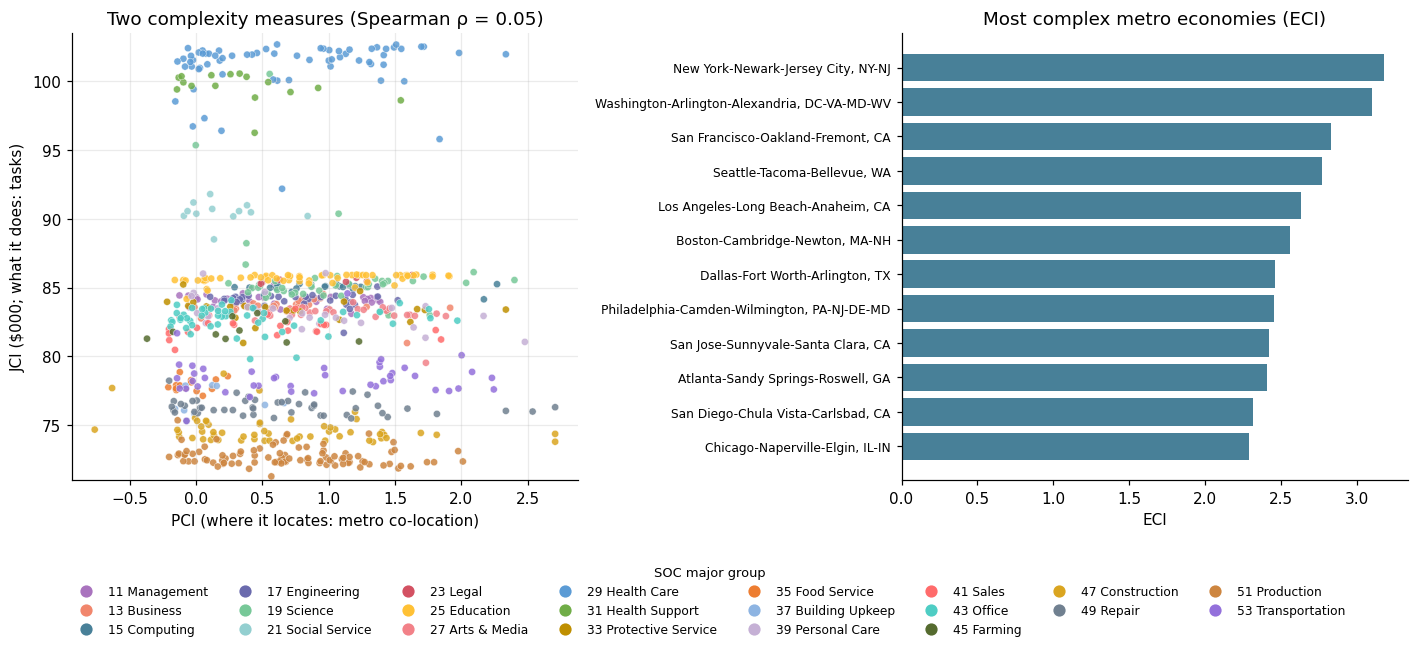

PCI correlates with log wage at r = 0.29, compared with r = 0.45 for JCI. The two indices are **essentially uncorrelated** (Spearman ρ = 0.05). They measure different things: JCI measures **what a job does** (the value of its task family), while PCI measures **where it can exist**. An occupation found only in large, diverse metros scores high on PCI whatever its tasks. Every task band in the left panel spans the full PCI range. The ECI ranking, by contrast, behaves as expected: the largest and most diversified metros come out on top.

In [13]:
occ_space = cs.build_occupation_space(oes)
occ["pci"] = pd.Series(occ_space["pci"])
both = occ.dropna(subset=["pci", "jci", "wage"])
rho = spearmanr(both.pci, both.jci).correlation
eci = pd.Series(occ_space["eci"]).sort_values(ascending=False)
names = {r: v["name"] for r, v in oes["regions"].items()}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(both.pci, both.jci / 1000, s=22, c=[MG_COLOR.get(g, "#999") for g in both.majorGroupId],
              alpha=0.85, edgecolors="white", linewidths=0.3)
ax[0].set_ylim(*(both.jci.quantile([0.005, 0.995]) / 1000 + np.array([-1, 1])))
ax[0].set(title=f"Two complexity measures (Spearman ρ = {rho:.2f})",
          xlabel="PCI (where it locates: metro co-location)", ylabel="JCI ($000; what it does: tasks)")
ax[0].grid(alpha=0.25)
top = eci.head(12)[::-1]
ax[1].barh([names[r] for r in top.index], top.values, color="#488098")
ax[1].tick_params(axis="y", labelsize=8)
ax[1].set(title="Most complex metro economies (ECI)", xlabel="ECI")
plt.tight_layout()
mg_legend(fig, both.majorGroupId.unique(), ncol=8)
plt.savefig(FIG_DIR / "04_pci_vs_jci_eci.png", bbox_inches="tight", dpi=120); plt.show()
display(Markdown(
    f"PCI correlates with log wage at r = {np.corrcoef(np.log(both.wage), both.pci)[0,1]:.2f}, "
    f"compared with r = {np.corrcoef(np.log(both.wage), both.jci)[0,1]:.2f} for JCI. "
    f"The two indices are **essentially uncorrelated** (Spearman ρ = {rho:.2f}). They measure different things: "
    "JCI measures **what a job does** (the value of its task family), while PCI measures **where it can exist**. "
    "An occupation found only in large, diverse metros scores high on PCI whatever its tasks. "
    "Every task band in the left panel spans the full PCI range. "
    "The ECI ranking, by contrast, behaves as expected: the largest and most diversified metros come out on top."))

## 7. From complexity to space: the propensity graphs

Both networks use the **minimum conditional probability** proximity of the Product Space (Hidalgo et al., 2007):
$$\phi_{ab} = \frac{\sum_x M_{xa} M_{xb}}{\max\big(k_a, k_b\big)} = \min\big\{P(a \mid b),\, P(b \mid a)\big\}$$

- In the **Job Space**, $x$ ranges over tasks. Two jobs are close when most of the tasks of the more varied job are also performed by the other. Skills should transfer easily between such jobs, in the spirit of the skill-relatedness of Neffke & Henning (2013).
- In the **Occupation Space**, $x$ ranges over metros. Two occupations are close when metros that specialise in one tend to specialise in the other. This is the direct analogue of the Atlas Product Space and the Metroverse Industry Space.

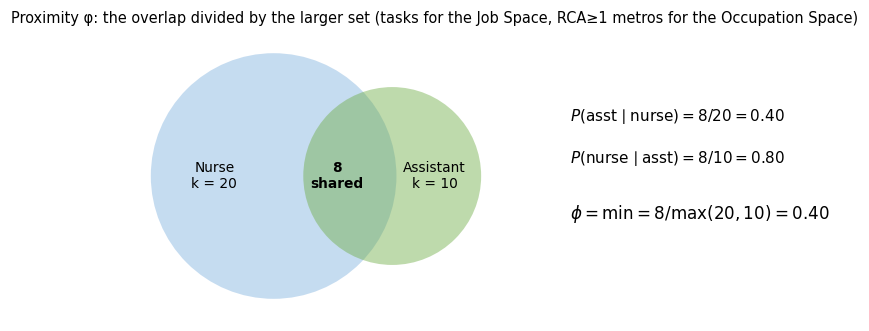

In [14]:
def proximity_diagram():
    """Explanatory figure: phi = shared / max(k) for two jobs."""
    from matplotlib.patches import Circle
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.set_xlim(0, 9); ax.set_ylim(0, 3.4); ax.axis("off"); ax.set_aspect("equal")
    ax.add_patch(Circle((2.6, 1.7), 1.45, fc=MG_COLOR.get("29", "#c55"), alpha=0.35, ec="none"))
    ax.add_patch(Circle((4.0, 1.7), 1.05, fc=MG_COLOR.get("31", "#e88"), alpha=0.45, ec="none"))
    ax.text(1.9, 1.7, "Nurse\nk = 20", ha="center", va="center", fontsize=9)
    ax.text(4.5, 1.7, "Assistant\nk = 10", ha="center", va="center", fontsize=9)
    ax.text(3.35, 1.7, "8\nshared", ha="center", va="center", fontsize=9, weight="bold")
    ax.text(6.1, 2.35, r"$P(\mathrm{asst}\mid\mathrm{nurse}) = 8/20 = 0.40$", fontsize=10)
    ax.text(6.1, 1.85, r"$P(\mathrm{nurse}\mid\mathrm{asst}) = 8/10 = 0.80$", fontsize=10)
    ax.text(6.1, 1.2, r"$\phi = \min = 8/\max(20,10) = 0.40$", fontsize=11, weight="bold")
    ax.set_title("Proximity φ: the overlap divided by the larger set (tasks for the Job Space, "
                 "RCA≥1 metros for the Occupation Space)", fontsize=9.5)
    plt.savefig(FIG_DIR / "00d_proximity.png", bbox_inches="tight", dpi=120); plt.show()

proximity_diagram()

Taking the *minimum* of the two conditional probabilities keeps a very general job (many tasks) from looking close to everything.

**Making the graph readable** follows the Atlas recipe:
1. Build a *maximum spanning tree* on φ, so every occupation is connected through its strongest links.
2. Add each node's top-k links, with k chosen so the average degree is about 4–5.
3. Lay out the nodes with Kamada-Kawai on the tree, then refine with a force layout on the full backbone.
4. Group nodes into **knowledge clusters** with Louvain community detection at two resolutions.

Positions are computed once offline and shipped to the website as fixed x/y coordinates.

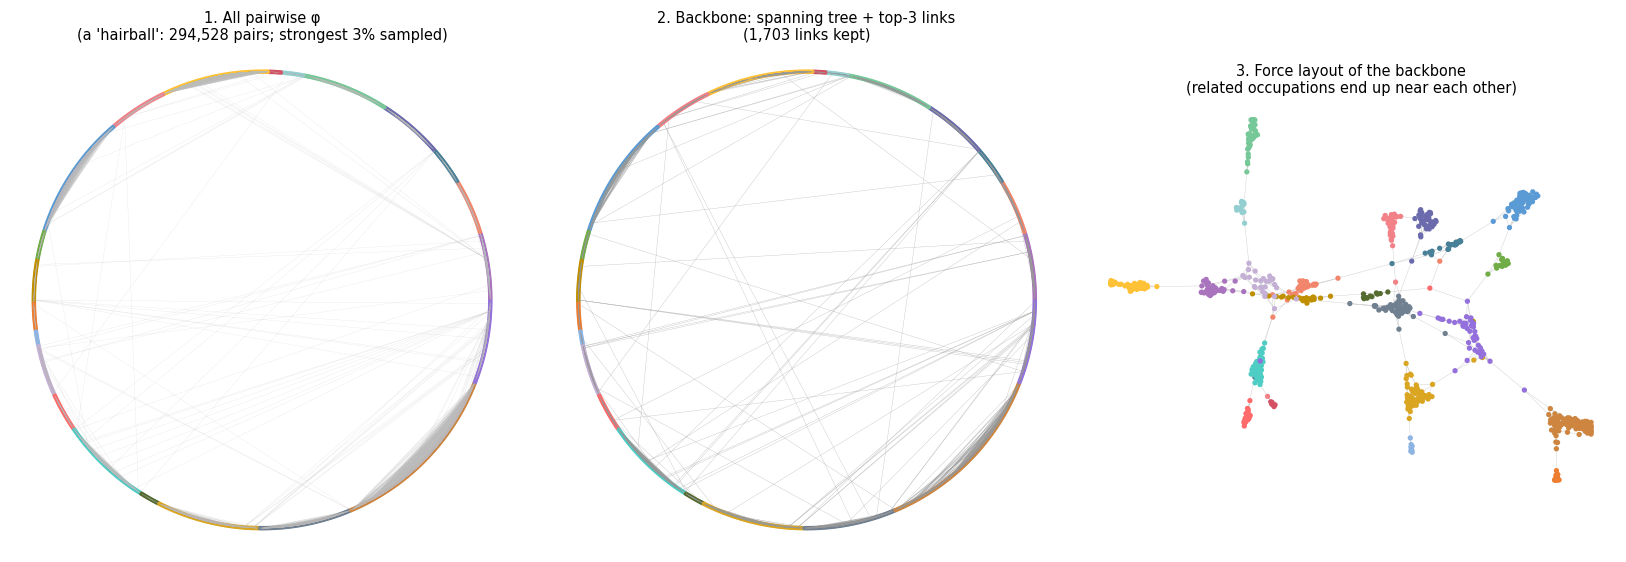

In [15]:
def draw(space, title, ax, color_values=None, cmap="viridis"):
    codes = space["codes"]; n = len(codes)
    edges, k, cutoff, mst = cs.backbone(space["phi"], 4.0)
    xy = cs.layout(n, edges, mst, seed=42)
    for i, j, w in edges:
        ax.plot(*xy[[i, j]].T, color="#d0d0d0", lw=0.35, zorder=1)
    if color_values is None:
        c = [MG_COLOR.get(occ.loc[code, "majorGroupId"], "#999") for code in codes]
        ax.scatter(*xy.T, s=9, c=c, zorder=2, edgecolors="none")
    else:
        v = np.array([color_values.get(code, np.nan) for code in codes])
        sc = ax.scatter(*xy.T, s=9, c=v, cmap=cmap, zorder=2, edgecolors="none")
        plt.colorbar(sc, ax=ax, shrink=0.6)
    ax.set_title(f"{title}\n{n} occupations · {len(edges)} links · top-{k} + MST · φ ≥ {cutoff:.2f}", fontsize=10)
    ax.set_aspect("equal"); ax.axis("off")

def pipeline_diagram(space):
    """Explanatory figure: dense phi network -> MST + top-k backbone -> laid-out map."""
    codes = space["codes"]; n = len(codes)
    phi = space["phi"]
    edges, k, cutoff, mst = cs.backbone(phi, 4.0)
    xy = cs.layout(n, edges, mst, seed=42)
    col = [MG_COLOR.get(occ.loc[c, "majorGroupId"], "#999") for c in codes]
    rng = np.random.default_rng(1)
    circ = np.c_[np.cos(np.linspace(0, 2 * np.pi, n, endpoint=False)), np.sin(np.linspace(0, 2 * np.pi, n, endpoint=False))]
    iu = np.triu_indices(n, 1)
    strong = np.where(phi[iu] >= np.quantile(phi[iu], 0.97))[0]
    sample = rng.choice(strong, size=min(4000, len(strong)), replace=False)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    for e in sample:
        i, j = iu[0][e], iu[1][e]
        ax[0].plot(*circ[[i, j]].T, color="#bbb", lw=0.15, alpha=0.5)
    ax[0].scatter(*circ.T, s=4, c=col)
    ax[0].set_title(f"1. All pairwise φ\n(a 'hairball': {len(iu[0]):,} pairs; strongest 3% sampled)", fontsize=9.5)
    for i, j, w in edges:
        ax[1].plot(*circ[[i, j]].T, color="#999", lw=0.25, alpha=0.6)
    ax[1].scatter(*circ.T, s=4, c=col)
    ax[1].set_title(f"2. Backbone: spanning tree + top-{k} links\n({len(edges):,} links kept)", fontsize=9.5)
    for i, j, w in edges:
        ax[2].plot(*xy[[i, j]].T, color="#d0d0d0", lw=0.3)
    ax[2].scatter(*xy.T, s=6, c=col, zorder=2)
    ax[2].set_title("3. Force layout of the backbone\n(related occupations end up near each other)", fontsize=9.5)
    for a in ax:
        a.set_aspect("equal"); a.axis("off")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "00e_pipeline.png", bbox_inches="tight", dpi=110); plt.show()

pipeline_diagram(job_space)

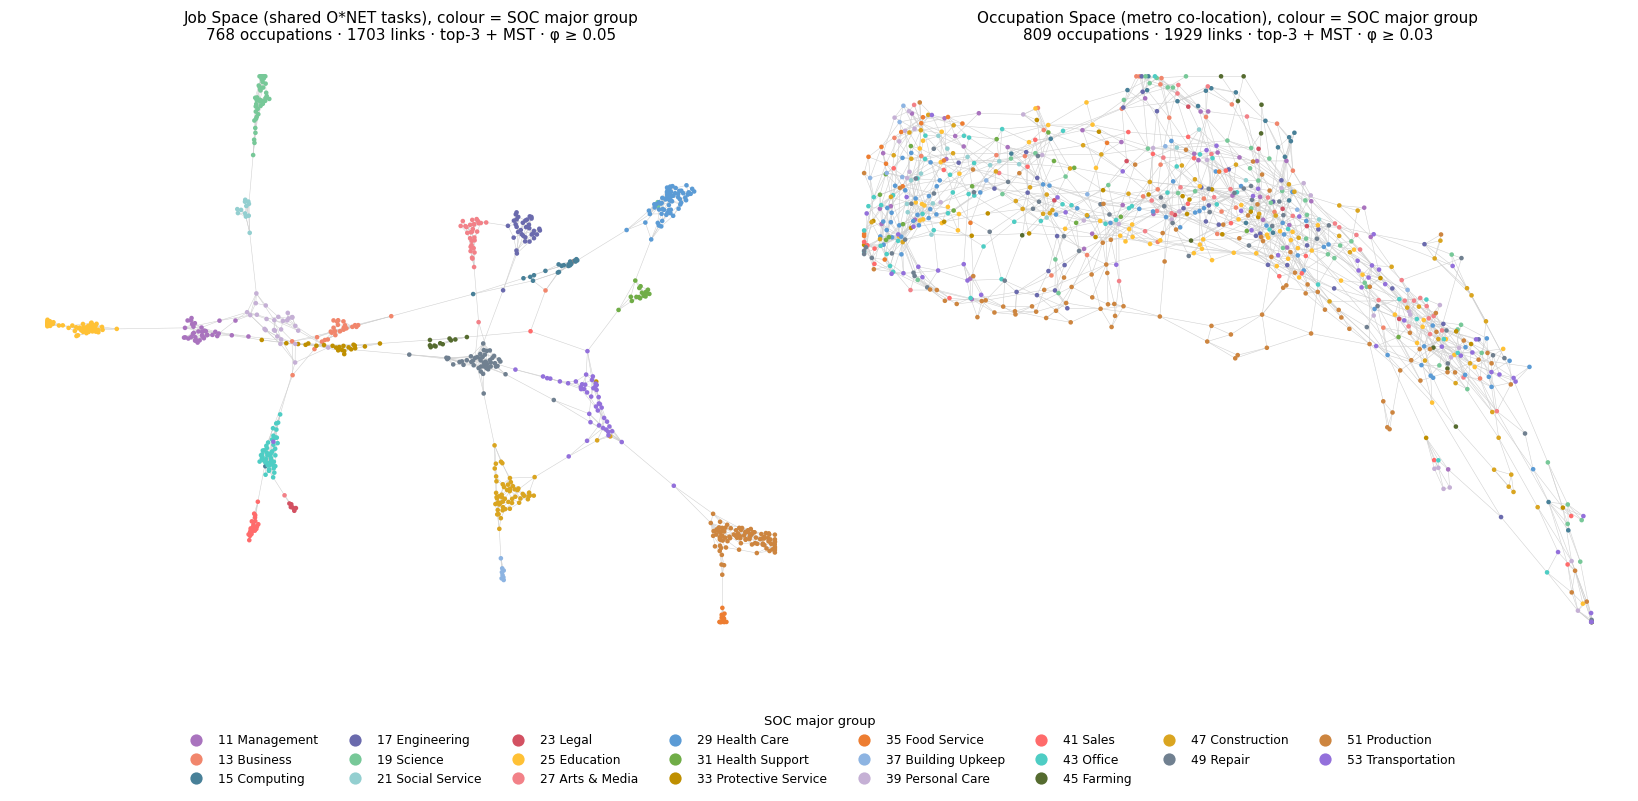

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6.2))
draw(job_space, "Job Space (shared O*NET tasks), colour = SOC major group", ax[0])
draw(occ_space, "Occupation Space (metro co-location), colour = SOC major group", ax[1])
plt.tight_layout()
mg_legend(fig, occ.majorGroupId.unique(), ncol=8)
plt.savefig(FIG_DIR / "05_spaces.png", bbox_inches="tight", dpi=130); plt.show()

In [17]:
import networkx as nx

def cluster_summary(space):
    codes = space["codes"]; n = len(codes)
    edges, _, _, _ = cs.backbone(space["phi"], 4.0)
    cont, _ = cs.clusters(n, edges, seed=42)
    G = nx.Graph(); G.add_nodes_from(range(n))
    for i, j, w in edges:
        G.add_edge(i, j, weight=w)
    comms = [set(np.where(cont == c)[0]) for c in np.unique(cont)]
    mod = nx.community.modularity(G, comms, weight="weight")
    groups = np.array([occ.loc[c, "majorGroupName"] for c in codes])
    purity = np.mean([pd.Series(groups[list(c)]).value_counts(normalize=True).iloc[0] for c in comms])
    rows = []
    for c in comms:
        vc = pd.Series(groups[list(c)]).value_counts(normalize=True)
        rows.append({"occupations": len(c),
                     "top SOC major groups (share of cluster)": ", ".join(f"{g} {s:.0%}" for g, s in vc.head(3).items())})
    return mod, purity, pd.DataFrame(rows).sort_values("occupations", ascending=False)

mod_j, pur_j, _ = cluster_summary(job_space)
mod_o, pur_o, tab_o = cluster_summary(occ_space)
display(Markdown(
    f"| | Job Space | Occupation Space |\n|---|---|---|\n"
    f"| Modularity of the knowledge clusters | {mod_j:.2f} | {mod_o:.2f} |\n"
    f"| Average share of a cluster from its largest SOC major group | {pur_j:.0%} | {pur_o:.0%} |"))
display(Markdown("**Occupation Space: composition of the high-aggregation knowledge clusters**"))
display(tab_o.style.hide(axis="index"))

| | Job Space | Occupation Space |
|---|---|---|
| Modularity of the knowledge clusters | 0.90 | 0.74 |
| Average share of a cluster from its largest SOC major group | 91% | 21% |

**Occupation Space: composition of the high-aggregation knowledge clusters**

occupations,top SOC major groups (share of cluster)
217,"Production 14%, Educational Instruction and Library 11%, Construction and Extraction 8%"
134,"Construction and Extraction 12%, Production 12%, Transportation and Material Moving 12%"
117,"Educational Instruction and Library 13%, Construction and Extraction 11%, Installation, Maintenance, and Repair 9%"
86,"Healthcare Practitioners and Technical 27%, Office and Administrative Support 17%, Educational Instruction and Library 13%"
76,"Construction and Extraction 13%, Food Preparation and Serving Related 12%, Office and Administrative Support 11%"
76,"Production 53%, Transportation and Material Moving 12%, Architecture and Engineering 9%"
71,"Computer and Mathematical 21%, Business and Financial Operations 20%, Life, Physical, and Social Science 18%"
32,"Life, Physical, and Social Science 16%, Transportation and Material Moving 16%, Installation, Maintenance, and Repair 9%"


Both maps contain strong communities (high modularity), but they are organised differently:

- **The Job Space is organised by occupational family.** Occupations in a family share tasks, so each cluster is dominated by one SOC major group: healthcare, education, construction trades, production and so on.
- **The Occupation Space mixes families.** Metros specialise in *combinations* of occupations, so each knowledge cluster draws on several SOC major groups, as the composition table above shows. The relatedness that matters for regional diversification therefore cuts across the official occupational hierarchy. This is the same pattern Muneepeerakul et al. (2013) found for US metros.

**Propensity.** For a region, the relatedness density of an occupation it lacks is
$$\omega_{cp} = \frac{\sum_{p'} M_{cp'}\,\phi_{pp'}}{\sum_{p'} \phi_{pp'}}$$
This measures how much of the occupation's neighbourhood the region already has. High-density absent occupations are its most feasible next steps. Combining density with PCI or JCI shows which of those steps also raise complexity (Hausmann et al., 2014, "complexity outlook gain").

**Explore it interactively →** On any US region page, open the [**Occupation Space** tab](../../#/city/national-us/occupation-space?space=job). Toggle between the Occupation Space and the Job Space, and colour the nodes by PCI or JCI.

## 8. Limitations and next steps

- **JCI is wage-anchored.** It inherits whatever distortions exist in wages, such as rents, discrimination or monopsony, and it depends on the number of iterations. It ranks jobs well but is not a structural estimate of productivity.
- **Binary tasks.** Treating every listed DWA equally ignores task importance. Model 2/3 variants weighted by importance can be tried in the playground notebook (`notebooks/space-playground/`).
- **OES suppression.** Small metro × occupation cells are suppressed by BLS and enter the RCA as zeros. This adds noise to the Occupation Space, especially for rare occupations.
- **Validation.** A natural next step is checking job proximity against observed worker transitions, such as the O\*NET *Career Changers* matrix or CPS flows (Neffke & Henning, 2013). That check, and a Growth Opportunities view built on density, are next.

## References

- Acemoglu, D. & Autor, D. (2011). Skills, tasks and technologies: implications for employment and earnings. *Handbook of Labor Economics* 4B.
- Acemoglu, D. & Restrepo, P. (2018). The race between man and machine. *American Economic Review* 108(6).
- Acemoglu, D. & Restrepo, P. (2019). Automation and new tasks. *Journal of Economic Perspectives* 33(2).
- Acemoglu, D. & Restrepo, P. (2022). Tasks, automation, and the rise in US wage inequality. *Econometrica* 90(5).
- Autor, D. H., Levy, F. & Murnane, R. J. (2003). The skill content of recent technological change: an empirical exploration. *Quarterly Journal of Economics* 118(4).
- Hausmann, R. & Hidalgo, C. A. (2011). The network structure of economic output. *Journal of Economic Growth* 16(4).
- Alabdulkareem, A., Frank, M. R., Sun, L., AlShebli, B., Hidalgo, C. & Rahwan, I. (2018). Unpacking the polarization of workplace skills. *Science Advances* 4(7).
- Hausmann, R., Hidalgo, C. A., et al. (2014). *The Atlas of Economic Complexity*. MIT Press. [atlas.hks.harvard.edu](https://atlas.hks.harvard.edu/)
- Hidalgo, C. A., Klinger, B., Barabási, A.-L. & Hausmann, R. (2007). The product space conditions the development of nations. *Science* 317.
- Hidalgo, C. A. & Hausmann, R. (2009). The building blocks of economic complexity. *PNAS* 106(26).
- Mealy, P., Farmer, J. D. & Teytelboym, A. (2019). Interpreting economic complexity. *Science Advances* 5(1).
- Muneepeerakul, R., Lobo, J., Shutters, S. T., Gómez-Liévano, A. & Qubbaj, M. R. (2013). Urban economies and occupation space. *PLoS ONE* 8(9).
- Neffke, F. & Henning, M. (2013). Skill relatedness and firm diversification. *Strategic Management Journal* 34(3).
- Growth Lab. *Metroverse* ([metroverse.hks.harvard.edu](https://metroverse.hks.harvard.edu/)) and *py-ecomplexity* ([github.com/cid-harvard/py-ecomplexity](https://github.com/cid-harvard/py-ecomplexity)).